In [1]:
import sys
sys.path.append("../src")

In [2]:
import pandas as pd
from pathlib import Path
from modelado import asignar_estaciones, calcular_maximos_estacionales, pronostico_ingenuo, preparar_serie_hw, pronosticar_hw

In [3]:
ruta_serie = Path("../data/processed/SERIE_TRABAJO_CTRELEUW.csv")
serie = pd.read_csv(ruta_serie, parse_dates=["MES"])
serie.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   MES                        93 non-null     datetime64[us]
 1   MAX_REAL_MW                93 non-null     float64       
 2   POTENCIA_DECLARADA_MW      93 non-null     float64       
 3   EDICION                    93 non-null     str           
 4   DESCARGA                   93 non-null     str           
 5   REVISADO                   93 non-null     bool          
 6   POSIBLE_COPIA_DECLARACION  93 non-null     bool          
 7   TEMPERATURA_MEDIA_C        93 non-null     float64       
 8   TEMPERATURA_MAX_C          93 non-null     float64       
 9   TEMPERATURA_MIN_C          93 non-null     float64       
dtypes: bool(2), datetime64[us](1), float64(5), str(2)
memory usage: 7.7 KB


In [4]:
serie = asignar_estaciones(serie)
serie.head()

,MES,MAX_REAL_MW,POTENCIA_DECLARADA_MW,EDICION,DESCARGA,REVISADO,POSIBLE_COPIA_DECLARACION,TEMPERATURA_MEDIA_C,TEMPERATURA_MAX_C,TEMPERATURA_MIN_C,ESTACION,ANIO_ESTACION
0,2019-01-01,44.221,44.426,2022-12,2026-10-13,False,False,21.974194,39.5,8.0,VERANO,2018
1,2019-02-01,45.960,44.798,2022-12,2026-10-13,False,False,21.007143,40.2,7.5,VERANO,2018
2,2019-03-01,43.629,43.833,2022-12,2026-10-13,False,False,18.341935,35.2,7.0,VERANO,2018
3,2019-04-01,43.363,43.567,2022-12,2026-10-13,False,False,16.016667,29.0,2.9,VERANO,2018
4,2019-05-01,44.244,44.427,2022-12,2026-10-13,False,False,11.293548,23.9,-1.7,INVIERNO,2019


In [5]:
maximos_estacionales = calcular_maximos_estacionales(serie)

In [6]:
maximos_estacionales[maximos_estacionales["MESES"] < 6]

,ANIO_ESTACION,ESTACION,MAXIMO_MW,MESES,COMPLETA,PICO_CON_COPIA,UTILIZABLE
15,2026,INVIERNO,44.004,5,False,False,False
0,2018,VERANO,45.960,4,False,False,False


In [7]:
maximos_estacionales = pronostico_ingenuo(maximos_estacionales)

In [8]:
maximos_estacionales["UTILIZABLE"].value_counts()

UTILIZABLE
True     13
False     3
Name: count, dtype: int64

In [9]:
maximos_estacionales["EVALUABLE"].value_counts()

EVALUABLE
True     10
False     6
Name: count, dtype: int64

In [10]:
maximos_estacionales.head()

,ANIO_ESTACION,ESTACION,MAXIMO_MW,MESES,COMPLETA,PICO_CON_COPIA,UTILIZABLE,PRONOSTICO_ANT,EVALUABLE,ERROR_MW
1,2019,INVIERNO,45.579,6,True,False,True,NaN,False,NaN
3,2020,INVIERNO,42.805,6,True,True,False,45.579,False,-2.774
5,2021,INVIERNO,42.352,6,True,False,True,NaN,False,NaN
7,2022,INVIERNO,44.156,6,True,False,True,42.352,True,1.804
9,2023,INVIERNO,42.448,6,True,False,True,44.156,True,-1.708


In [11]:
evaluables = (maximos_estacionales["EVALUABLE"] == True) 
mae_referencia = (maximos_estacionales.loc[evaluables,"ERROR_MW"].abs()).mean()
sesgo_referencia = maximos_estacionales.loc[evaluables,"ERROR_MW"].mean()
print("MAE: ", mae_referencia.round(3))
print("SESGO REFERENCIA: ", sesgo_referencia.round(3))

MAE:  1.676
SESGO REFERENCIA:  0.414


In [12]:
mayores = maximos_estacionales.loc[evaluables,"ERROR_MW"] > 0 
mayores.sum()

np.int64(5)

In [13]:
serie_mensual = serie.set_index("MES")["MAX_REAL_MW"].asfreq("MS")
serie_mensual.index

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

<Axes: xlabel='MES'>

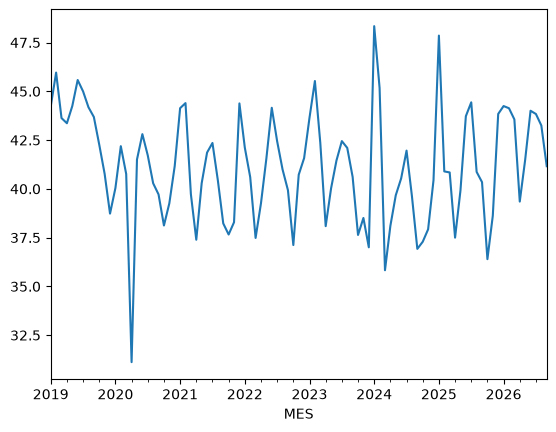

In [14]:
serie_mensual.plot()

In [15]:
serie_hw = preparar_serie_hw(serie)

In [16]:
serie_hw.loc["2020-04-01"]

np.float64(39.00828571428571)

In [17]:
pronostico_hw = pronosticar_hw(serie_hw,7)

In [18]:
pico_hw = pronostico_hw["2026-11-01":"2027-04-01"].max()
pico_hw

np.float64(45.21945060214759)

In [19]:
veranos = (maximos_estacionales["ESTACION"] == "VERANO")
maximos_estacionales[veranos]

,ANIO_ESTACION,ESTACION,MAXIMO_MW,MESES,COMPLETA,PICO_CON_COPIA,UTILIZABLE,PRONOSTICO_ANT,EVALUABLE,ERROR_MW
0,2018,VERANO,45.960,4,False,False,False,NaN,False,NaN
2,2019,VERANO,42.187,6,True,False,True,NaN,False,NaN
4,2020,VERANO,44.396,6,True,False,True,42.187,True,2.209
6,2021,VERANO,44.380,6,True,False,True,44.396,True,-0.016
8,2022,VERANO,45.528,6,True,False,True,44.380,True,1.148
10,2023,VERANO,48.340,6,True,False,True,45.528,True,2.812
12,2024,VERANO,47.856,6,True,False,True,48.340,True,-0.484
14,2025,VERANO,44.244,6,True,False,True,47.856,True,-3.612
